# Reducing Bias With Boosting

## About This Project

In this project, you will reduce bias by implementing Gradient Boosted Regression Trees (GBRTs).

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter Notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

### Getting Started

Before you get started, let's import a few packages that you will need.

In [1]:
import numpy as np
from numpy.matlib import repmat
from scipy.io import loadmat
import time

# Interactive plots
%matplotlib ipympl
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version: %s" % sys.version.split(" ")[0])

Python version: 3.12.5


In this project, we will work with an artificial 2D spiral dataset of size 150 (for visualization), and a high-dimensional dataset [ION](https://archive.ics.uci.edu/ml/datasets/Ionosphere) (for a binary test classification problem).

In [2]:
# Generate 2D spiral training and test datasets for visualization
xTrSpiral, yTrSpiral, xTeSpiral, yTeSpiral = spiraldata(150)

# Generate high-dimensional dataset for binary test classification
xTrIon, yTrIon, xTeIon, yTeIon = iondata()

You will use the regression tree from a previous project. As a reminder, the following code shows you how to fit a decision tree and make predictions:

In [3]:
# Create a regression tree with depth 4
tree = RegressionTree(depth=4)

# Fit/train the regression tree on the spiral training dataset
tree.fit(xTrSpiral, yTrSpiral)

# Use trained regression tree to predict scores for training data
score = tree.predict(xTrSpiral)

# Use trained regression tree to make a +1/-1 prediction
pred = np.sign(score)

Now run the following cell that evaluates your `depth=4` decision tree on the training set and test set. You might see that the difference between training error and test error is small (no overfitting) but both the errors are rather high. This is a sign of underfitting or high bias. 

In [4]:
# Calculate training and test error for the regression tree with depth 4
train_error = np.mean(np.sign(tree.predict(xTrSpiral)) != yTrSpiral)
test_error = np.mean(np.sign(tree.predict(xTeSpiral)) != yTeSpiral)
print(f"Training Error: {100 * train_error:.2f}%")
print(f"Test Error: {100 * test_error:.2f}%")

Training Error: 31.33%
Test Error: 33.33%


To convince you further that the `depth=4` tree is underfitting, we create the following `visclassifier` function, which plots the decision boundary of a classifier in two dimensions. Execute the following code to see what the decision boundary of your tree looks like on the spiral dataset.

Training Error: 31.33%
Test Error: 33.33% (test points not shown in figure below)


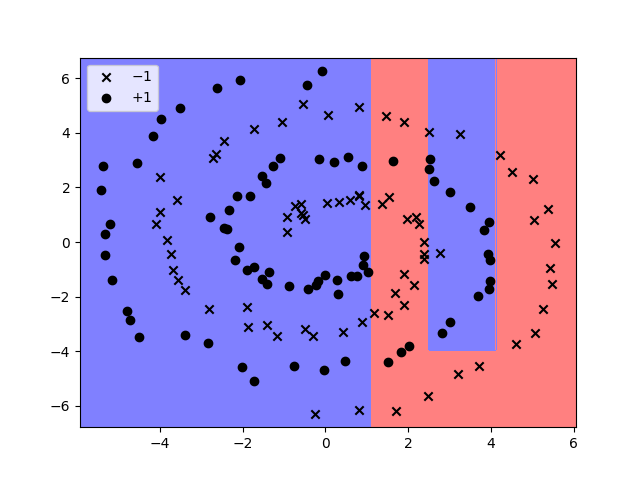

In [5]:
def visclassifier(fun, xTr, yTr, newfig=True, color=True):
    """
    Visualize the classifier and decision boundary.
    Define the symbols and colors we'll use in the plots later.
    """
    yTr = np.array(yTr).flatten()

    # Get the class values from training labels
    classvals = np.unique(yTr)

    # Return 300 evenly spaced numbers over this interval
    res = 300
    xrange = np.linspace(min(xTr[:, 0]) - 0.5, max(xTr[:, 0]) + 0.5, res)
    yrange = np.linspace(min(xTr[:, 1]) - 0.5, max(xTr[:, 1]) + 0.5, res)

    # Repeat this matrix 300 times for both axes
    pixelX = repmat(xrange, res, 1)
    pixelY = repmat(yrange, res, 1).T

    # Test all of these points on the grid
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    testpreds = fun(xTe)

    # Reshape test predictions to make the new grid
    Z = testpreds.reshape(res, res)
    Z[0, 0] = 1  # Optional: scale the colors correctly

    # Plot configuration
    if newfig:
        plt.figure()

    labels = ["$-1$", "$+1$"]                  # Negative and positive points
    symbols = ["x", "o"]                       # x for -1 and o (circle) for +1
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1 and blue for +1

    # Fill in the contours for these predictions
    if color == True:
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)
    else:
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=["gray", "gray"])

    # Plot training data: "x" for -1 and "o" for +1
    for idx, c in enumerate(classvals):
        plt.scatter(
            xTr[yTr == c, 0],     # x-coordinate of point
            xTr[yTr == c, 1],     # y-coordinate of point
            label=labels[idx],    # Label of point (-1 or +1)         
            marker=symbols[idx],  # Marker of point ("x" or "o")
            color="black",        # Color of point
        )

    plt.legend(loc="upper left")
    plt.axis("tight")
    plt.show()


# Calculate training and test error for the regression tree with depth 4
train_error = np.mean(np.sign(tree.predict(xTrSpiral)) != yTrSpiral)
test_error = np.mean(np.sign(tree.predict(xTeSpiral)) != yTeSpiral)
print(f"Training Error: {100 * train_error:.2f}%")
print(f"Test Error: {100 * test_error:.2f}% (test points not shown in figure below)")

visclassifier(lambda X: tree.predict(X), xTrSpiral, yTrSpiral)
plt.title("Regression Tree Classifier");

As you can see from the graph above, the `depth=4` tree is too simple and is not capable of capturing the inherit information of the dataset. 

## Gradient Boosting Regression Tree in Action

### Part One: Implement `evalboostforest` [Graded]

CART trees are known to be high variance classifiers if trained to full depth. However, if you build trees of small depth (e.g., only `depth=3` or `depth=4`), the trees do not overfit as we see above. Instead, they suffer from **high bias** and thus **underfit**. We can reduce the bias of a classifier with gradient boosting.

Before implementing Gradient Boosted Regression Trees, you will implement **`evalboostforest`** with an additional argument `alphas` that lets you weigh the trees' predictions with any weights (in bagging, all weights `alpha[i]` were equal).

Similar to bagging, the `evalboostforest` is provided a list of $m$ trees $\left[ h_1, \dots, h_m \right]$ and $n$ data points that are $d$-dimensional. However, this time, the function will weigh each tree $h_j$ according to $\alpha_j$.

More precisely, for each test sample $\mathbf{x}_i$, `evalboostforest` should output the following prediction:

$$
H(\mathbf{x}_i) = \sum_{j=1}^m \alpha_j h_j(\mathbf{x}_i)
$$

In [6]:
def evalboostforest(trees, X, alphas=None):
    """
    Evaluates data points X using trees using weights alphas (optional).

    Input:
        trees: List of length m of RegressionTree decision trees
        X: nxd matrix of data points
        alphas: m-dimensional weight vector for the ensemble's prediction

    Output:
        pred: n-dimensional vector of predictions
    """
    m = len(trees)
    n, _ = X.shape

    if alphas is None:
        alphas = np.ones(m) / len(trees)

    pred = np.zeros(n)

    # YOUR CODE HERE
    for tree, alpha in zip(trees, alphas):
        pred += alpha * tree.predict(X)
    # END OF YOUR CODE

    return pred

Run the next cell to check your implementation of `evalboostforest`.

In [7]:
def evalboostforest_test1():
    """
    Check that predictions have the correct shape
    """
    m = 200
    x = np.arange(100).reshape((100, 1))
    y = np.arange(100)
    trees = forest(x, y, m)  # Create a list of m trees
    preds = evalboostforest(trees, x)
    return preds.shape == y.shape


def evalboostforest_test2():
    """
    Check that prediction values are correct
    """
    m = 200
    x = np.random.rand(10, 3)
    y = np.ones(10)
    x2 = np.random.rand(10, 3)
    max_depth = 0

    # Create a forest with trees depth 0.
    # Since the data are all ones, each tree will return 1 as prediction.
    trees = forest(x, y, m, max_depth)  # Create a list of m trees
    pred = evalboostforest(trees, x2)[0]

    # Prediction should be equal to the sum of weights
    return np.isclose(pred, 1)


def evalboostforest_test3():
    """
    Results should match evalforest() if alphas are 1/m and labels are +1, -1
    """
    m = 20
    x = np.arange(100).reshape((100, 1))
    y = np.sign(np.arange(100))
    trees = forest(x, y, m)  # Create a list of m trees

    alphas = np.ones(m) / m
    preds1 = evalforest(trees, x)  # Evaluate forest using our implementation
    preds2 = evalboostforest(trees, x, alphas)

    return np.all(np.isclose(preds1, preds2))


def evalboostforest_test4():
    """
    If only alpha[i]=1 and all others are 0, then the result
    should match exactly the predictions of the i-th tree.
    """
    m = 20
    x = np.random.rand(100, 5)
    y = np.arange(100)
    x2 = np.random.rand(20, 5)

    trees = forest(x, y, m)  # Create a list of m trees
    allmatch = True
    for i in range(m):  # Go through each tree i
        alphas = np.zeros(m)
        alphas[i] = 1.0  # Set only alpha[i]=1 all other alpha=0
        preds1 = trees[i].predict(x2)  # Get prediction of i-th tree
        preds2 = evalboostforest(
            trees, x2, alphas
        )  # Get prediction of weighted ensemble
        allmatch = allmatch and all(np.isclose(preds1, preds2))

    return allmatch


runtest(evalboostforest_test1, "evalboostforest_test1")
runtest(evalboostforest_test2, "evalboostforest_test2")
runtest(evalboostforest_test3, "evalboostforest_test3")
runtest(evalboostforest_test4, "evalboostforest_test4")

Running Test: evalboostforest_test1 ... ✔ Passed!
Running Test: evalboostforest_test2 ... ✔ Passed!
Running Test: evalboostforest_test3 ... ✔ Passed!
Running Test: evalboostforest_test4 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (evalboostforest_test1)

In [ ]:
# Auto-graded test cell worth one point (evalboostforest_test2)

In [ ]:
# Auto-graded test cell worth one point (evalboostforest_test3)

In [ ]:
# Auto-graded test cell worth one point (evalboostforest_test4)

### Part Two: Implement `GBRT` [Graded]

Finally implement the function **`GBRT`**, which applies Gradient Boosting to the decision tree model. You can use the following pseudocode to write the function. You can also use your `evalboostforest` function to evaluate your boosted ensemble (provided you pass on the weights correctly).

<center>
    <img src="gbrt_pseudocode.png" width="500px" alt="Pseudocode for gradient boosted regression trees" />
</center>

In [10]:
def GBRT(xTr, yTr, m, maxdepth=4, alpha=0.1):
    """
    An implementation of Gradient Boosted Regression Trees with m trees of depth=maxdepth.

    Input:
        xTr: n x d matrix of data points
        yTr: n-dimensional vector of labels
        m: Number of trees in the forest
        maxdepth: Maximum depth of tree
        alpha: Learning rate for the GBRT (also the weight for each tree in the ensemble)


    Output:
        trees, alphas
        trees: List of decision trees of length m
        alphas: Weights of each tree
    """
    trees = []   # Initialize list for storing trees
    alphas = []  # Initialize list for storing alphas (weights)

    # Ensemble tree H = 0 right now; therefore, t_i = y_i for all i.
    # Make a copy of the ground truth label; this will be the initial
    # ground truth for the first GBRT.
    truth = np.copy(yTr)

    # For each iteration:
    # - Create a tree, fit to xTr and truth
    # - Append this tree to list of trees
    # - Append alpha to list of alphas
    # - Generate sum of weighted predictions of all trees with given alphas
    # - Calculate new truth values by subtracting weighted predictions from yTr
    # - Return list of trees and list of alphas

    # YOUR CODE HERE
    for i in range(m):
        tree = RegressionTree(maxdepth)
        tree.fit(xTr, truth)
        trees.append(tree)
        alphas.append(alpha)
        pred = evalboostforest(trees, xTr, alphas)
        truth = yTr - pred
    # END OF YOUR CODE

    return trees, alphas

The following code is a simple example of how to run your `GBRT` function on the spiral dataset:

```python
trees, weights = GBRT(xTrSpiral, yTrSpiral, 50)
```

Run the next cell to check your implementation `GBRT`.

In [11]:
def GBRT_test1():
    """
    Check for correct number of trees
    """
    m = 40
    x = np.arange(100).reshape((100, 1))
    y = np.arange(100)
    trees, weights = GBRT(x, y, m, alpha=0.1)
    return len(trees) == m and len(weights) == m


def GBRT_test2():
    """
    Check for correct max depth
    """
    m = 20
    x = np.arange(100).reshape((100, 1))
    y = np.arange(100)
    max_depth = 4
    trees, weights = GBRT(x, y, m, max_depth)
    depths_forest = np.array([tree.depth for tree in trees])
    return np.all(depths_forest == max_depth)


def GBRT_test3():
    """
    Check that errors decrease with more trees
    """
    np.random.seed(1)  # Seed the random number generator for consistency
    xTrSpiral, yTrSpiral, _, _ = spiraldata(150)
    
    # Create a gradient boosted forest with 4 trees
    m = 4
    max_depth = 4
    trees, weights = GBRT(xTrSpiral, yTrSpiral, m, max_depth, 1)

    errs = []
    for i in range(m):
        # Calculate the prediction of the first i-th tree
        predH = evalboostforest(trees[: i + 1], xTrSpiral, weights[: i + 1])
        
        # Calculate the error of the first i-th tree
        err = np.mean(np.sign(predH) != yTrSpiral)
        
        # Keep track of the error
        errs.append(err)

    # Your errs should be decreasing, i.e., the difference
    # between two subsequent errors should be <= 0
    return np.all(np.diff(errs) <= 0)


runtest(GBRT_test1, "GBRT_test1")
runtest(GBRT_test2, "GBRT_test2")
runtest(GBRT_test3, "GBRT_test3")

Running Test: GBRT_test1 ... ✔ Passed!
Running Test: GBRT_test2 ... ✔ Passed!
Running Test: GBRT_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (GBRT_test1)

In [ ]:
# Auto-graded test cell worth one point (GBRT_test2)

In [ ]:
# Auto-graded test cell worth one point (GBRT_test3)

### Visualize the Decision Boundary

The following script visualizes the decision boundary of a boosted ensemble of CART trees. It should perform much better than just one CART tree of the same depth.

Training Error: 0.67%
Test Error: 33.33% (test points not shown in figure below)


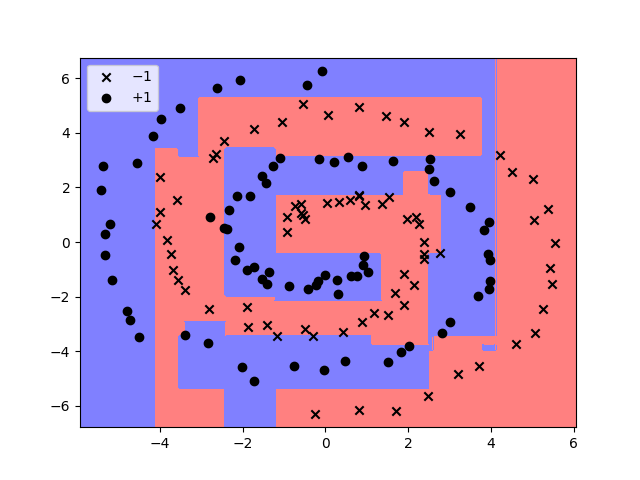

In [12]:
# Compute gradient boosted regression tree on training data
trees, weights = GBRT(xTrSpiral, yTrSpiral, 40, maxdepth=4, alpha=0.03)

# Compute training and testing error
training_error = np.mean(np.sign(evalforest(trees, xTrSpiral)) != yTrSpiral)
testing_error = np.mean(np.sign(evalforest(trees, xTeSpiral)) != yTeSpiral)
print(f"Training Error: {100 * training_error:.2f}%")
print(f"Test Error: {100 * test_error:.2f}% (test points not shown in figure below)")

# Visualize classifier and decision boundary
visclassifier(lambda X: evalboostforest(trees, X, weights), xTrSpiral, yTrSpiral)
plt.title("Gradient Boosted Regression Tree Classifier");

### Evaluate Training and Testing Error

The following script evaluates the training and testing error of an ensemble of CART trees as we vary the number of trees.

**NOTE:** The next cell takes about half a minute to run.

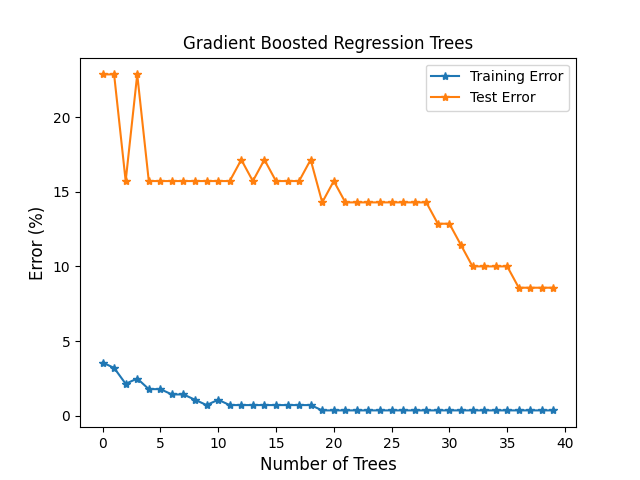

In [13]:
# Create boosted forest with max number of trees
M = 40  # Max number of trees
alltrees, allweights = GBRT(xTrIon, yTrIon, M, maxdepth=4, alpha=0.05)

# Calculate training and testing errors
err_trB = []  # Initialize list to store training errors
err_teB = []  # Initialize list to store test errors
for i in range(M):
    trees = alltrees[: i + 1]
    weights = allweights[: i + 1]
    trErr = np.mean(np.sign(evalboostforest(trees, xTrIon, weights)) != yTrIon)
    teErr = np.mean(np.sign(evalboostforest(trees, xTeIon, weights)) != yTeIon)
    err_trB.append(100 * trErr)  # Append percentage training error to list
    err_teB.append(100 * teErr)  # Append percentage test error to list

# Plot training and testing errors
plt.figure()
(line_tr,) = plt.plot(range(M), err_trB, "-*", label="Training Error")
(line_te,) = plt.plot(range(M), err_teB, "-*", label="Test Error")
plt.title("Gradient Boosted Regression Trees")
plt.legend(handles=[line_tr, line_te])
plt.xlabel("Number of Trees", fontsize=12)
plt.ylabel("Error (%)", fontsize=12)
plt.show()

### 2D Interactive Demo on Spiral Data (Add Trees With Clicks)

The following demo visualizes the GBRT classifier on the spiral data.

With each click you can add one more regression tree to the classifier, or you can `shift`+click to add ten more regression trees to the classifier.

**NOTE:** The next cell takes about half a minute to run.

Please keep in mind:
1. You must run (or rerun) this cell right before interacting with the plot.
2. You can either click to add one tree or shift+click to add 10 trees.
3. You may notice a slight delay when adding trees to the visualization.


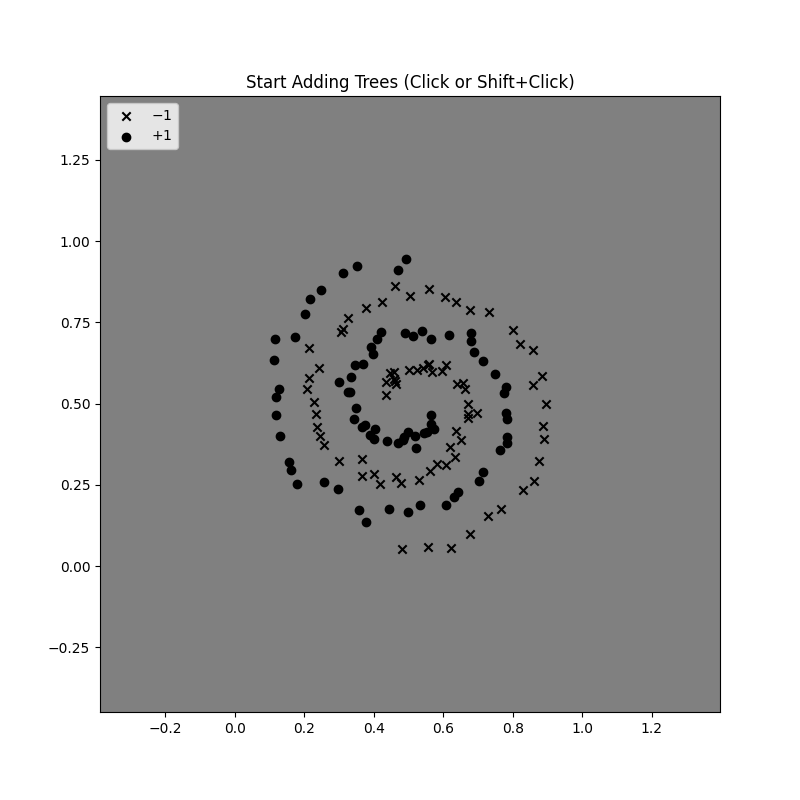

In [14]:
def onclick_spiral_classifier(event):
    """
    Visualize boosted classifier on spiral data by adding more trees
    """
    global xTrain, yTrain, xTest, yTest, M, Q, trees, weights

    if event.key == "shift":
        Q += 10
    else:
        Q += 1

    # Minimum between number of trees added (Q) and max number of trees (M)
    Q = min(Q, M)

    # Return 300 evenly spaced numbers over this interval
    res = 300
    xrange = np.linspace(0, 1, res)
    yrange = np.linspace(0, 1, res)

    # Repeat this matrix 300 times for both axes
    pixelX = repmat(xrange, res, 1)
    pixelY = repmat(yrange, res, 1).T

    # Create function for evaluating boosted forest
    fun = lambda X: evalboostforest(trees[:Q], X, weights[:Q])

    # Test all of these points on the grid
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    testpreds = fun(xTe)

    # Reshape the test predictions to make the new grid
    Z = testpreds.reshape(res, res)
    Z[0, 0] = 1  # Optional: scale the colors correctly

    # Plot configuration settings
    plt.cla()                                  # Clear axes
    plt.xlim((0, 1))                           # x-axis limits
    plt.ylim((0, 1))                           # y-axis limits
    labels_tr = ["$-1$ (Tr)", "$+1$ (Tr)"]     # Labels for training data
    symbols_tr = ["x", "o"]                    # "x" for -1 and "o" for +1 (training)
    labels_te = ["$-1$ (Te)", "$+1$ (Te)"]     # Labels for test data
    symbols_te = ["X", "."]                    # "X" for -1 and "." for +1 (test)
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1 and blue for +1 (predictions)

    # Fill in the contours for these predictions
    plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)

    # Plot training data: "x" for -1 and "o" for +1
    classvals = np.unique(yTrain)
    for idx, c in enumerate(classvals):
        plt.scatter(
            xTrain[yTrain == c, 0],  # x-coordinate of training point
            xTrain[yTrain == c, 1],  # y-coordinate of training point
            label=labels_tr[idx],    # Label of training point (-1 or +1)         
            marker=symbols_tr[idx],  # Marker of training point ("x" or "o")
            color="black",           # Color of training point
        )

    # Plot test data: "X" for -1 and and "." for +1
    classvals = np.unique(yTest)
    for idx, c in enumerate(classvals):
        plt.scatter(
            xTest[yTest == c, 0],    # x-coordinate of test point
            xTest[yTest == c, 1],    # y-coordinate of test point
            label=labels_te[idx],    # Label of test point (-1 or +1)         
            marker=symbols_te[idx],  # Marker of test point ("X" or ".")
            color="darkkhaki",       # Color of test point
        )

    # Calculate training error and test error
    tr_err = 100 * np.mean(np.sign(fun(xTrain)) != np.sign(yTrain))
    te_err = 100 * np.mean(np.sign(fun(xTest)) != np.sign(yTest))
    
    if Q == 1:
        plt.title(f"({Q} Tree) Training (Tr) Error: {tr_err:.2f}%, Test (Te) Error: {te_err:.2f}%")
    else:
        plt.title(f"({Q} Trees) Training (Tr) Error: {tr_err:.2f}%, Test (Te) Error: {te_err:.2f}%")

    plt.legend(loc="upper left")
    plt.axis("tight")
    plt.show()


# Generate training and test spiral data
xTrain = xTrSpiral.copy() / 14 + 0.5
yTrain = yTrSpiral.copy().astype(int)
xTest = xTeSpiral.copy() / 14 + 0.5
yTest = yTeSpiral.copy().astype(int)

# Hyperparameters (feel free to play with them)
M = 400       # Max number of trees for interactive demo
alpha = 0.05  # Learning rate
depth = 5     # Max depth of forest
trees, weights = GBRT(xTrain, yTrain, M, alpha=alpha, maxdepth=depth)
Q = 0         # Initial number of trees for interactive demo

# Interactive demo
print("Please keep in mind:")
print("1. You must run (or rerun) this cell right before interacting with the plot.")
print("2. You can either click to add one tree or shift+click to add 10 trees.")
print("3. You may notice a slight delay when adding trees to the visualization.")
fig = plt.figure(figsize=(8, 8))
plt.title("Start Adding Trees (Click or Shift+Click)")
visclassifier(lambda X: np.sum(X, 1) * 0, xTrain, yTrain, newfig=False, color=False)
plt.xlim(0, 1)
plt.ylim(0, 1)
cid = fig.canvas.mpl_connect("button_press_event", onclick_spiral_classifier)

### 1D Interactive Demo (Add Trees With Clicks)

The next interactive demo shows a 1-dimensional curve fitted with GBRT. We sample 100 training data points from the curve with additive noise. Note how the training and testing errors decrease as you add trees to your ensemble, but the testing error eventually increases again. Initially (with only a few trees) you will see that the predicted (red) curve is very smooth and then becomes increasingly less smooth as you add more trees (here you are decreasing bias).

In the end, the predicted curve becomes rather complicated and overfits to the training data (high variance). In this demo, you can nicely see how GBRT starts out with high bias (too smooth), then lowers the bias, but eventually ends up with high variance (very erratic overfitting curve). As with hyperparameters in Machine Learning, the number of trees in GBRT has a significant impact on the generalization error.

Please keep in mind:
1. You must run (or rerun) this cell right before interacting with the plot.
2. You can either click to add one tree or shift+click to add 10 trees.
3. You may notice a slight delay when adding trees to the visualization.


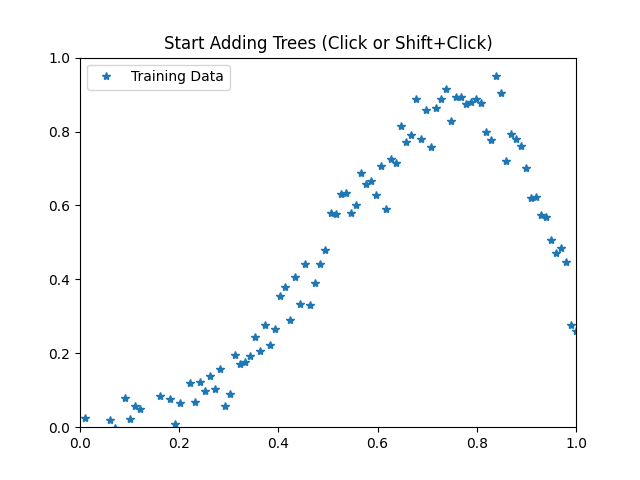

In [15]:
def onclick_forest(event):
    """
    Visualize boosted forest by adding more trees
    """
    global xTrain, yTrain, xTest, tTest, M, Q, trees, weights

    if event.key == "shift":
        Q += 10
    else:
        Q += 1

    # Minimum between number of trees added (Q) and max number of trees (M)
    Q = min(Q, M)

    # Preditions for training and test data
    pTrain = evalboostforest(trees[:Q], xTrain, weights[:Q])
    pTest = evalboostforest(trees[:Q], xTest, weights[:Q])

    # Plot configuration settings
    plt.cla()         # Clear axes
    plt.xlim((0, 1))  # x-axis limits
    plt.ylim((0, 1))  # y-axis limits
    
    plt.plot(xTrain[:, 0], yTrain, "*")  # Blue stars for training data
    plt.plot(xTest[:, 0], yTest, "k-.")  # Black dashed-dotted line for test data
    plt.plot(xTest[:, 0], pTest, "r-")   # Red dashed line for predictions on test data

    # Calculate mean squared error (MSE) for training and test data
    tr_MSE = np.sqrt(np.mean((pTrain - yTrain) ** 2))
    te_MSE = np.sqrt(np.mean((pTest - yTest) ** 2))
    
    if Q == 1:
        plt.title(f"({Q} Tree)  Training MSE: {tr_MSE:.4f}, Test MSE: {te_MSE:.4f}")
    else:
        plt.title(f"({Q} Trees)  Training MSE: {tr_MSE:.4f}, Test MSE: {te_MSE:.4f}")

    plt.legend(["Training Data", "Test Data", "Prediction"])
    plt.show()


# Generate training data and test data
n = 100
NOISE = 0.05
xTrain = np.array([np.linspace(0, 1, n), np.zeros(n)]).T
yTrain = 2 * np.sin(xTrain[:, 0] * 3) * (xTrain[:, 0] ** 2)
yTrain += np.random.randn(yTrain.size) * NOISE
ntest = 300
xTest = np.array([np.linspace(0, 1, ntest), np.zeros(ntest)]).T
yTest = 2 * np.sin(xTest[:, 0] * 3) * (xTest[:, 0] ** 2)

# Hyperparameters (feel free to play with them)
M = 400       # Max number of trees for interactive demo
alpha = 0.05  # Learning rate
depth = 3     # Max depth of forest
trees, weights = GBRT(xTrain, yTrain, M, alpha=alpha, maxdepth=depth)
Q = 0         # Initial number of trees for interactive demo

# Interactive demo
print("Please keep in mind:")
print("1. You must run (or rerun) this cell right before interacting with the plot.")
print("2. You can either click to add one tree or shift+click to add 10 trees.")
print("3. You may notice a slight delay when adding trees to the visualization.")
fig = plt.figure()
plt.title("Start Adding Trees (Click or Shift+Click)")
plt.plot(xTrain[:, 0], yTrain, "*")
plt.legend(["Training Data", "Testing Data"])
plt.xlim(0, 1)
plt.ylim(0, 1)
cid = fig.canvas.mpl_connect("button_press_event", onclick_forest)

### 2D Interactive Demo (Add Points With Clicks)

The following demo visualizes the GBRT classifier. Add your own points directly on the graph with click and `shift`+click to see the prediction boundaries. There will be a delay between clicks as the new classifier is trained.

Please keep in mind:
1. You must run (or rerun) this cell right before interacting with the plot.
2. Start the interactive demo by clicking the grid to add a positive point.
3. Click to add a positive point or shift+click to add a negative point.
4. You may notice a slight delay when adding points to the visualization.


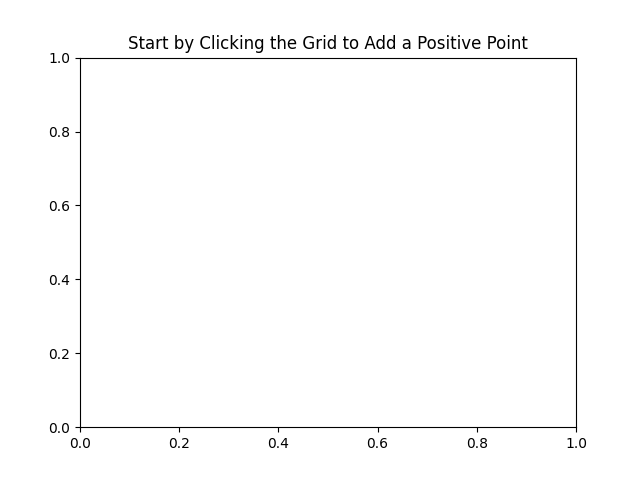

In [16]:
# Initialize empty array of width 2 to store training points
xTrain = np.empty((0, 2))

# Initialize empty array of width 1 to store training labels
yTrain = np.empty((0, 1))

# Number of trees
m = 5

def onclick_classifier(event):
    """
    Visualize boosted classifier by adding new points
    """
    global xTrain, yTrain, m

    # Shift+click to add a negative point.
    # Click to add a positive point.
    if event.key == "shift":
        label = -1
    else:
        label = 1

    # Create position vector for new point
    pos = np.array([[event.xdata, event.ydata]])

    # Add new point to training data
    xTrain = np.concatenate((xTrain, pos), axis=0)
    yTrain = np.append(yTrain, label)

    # Get the class values from training labels
    classvals = np.unique(yTrain)
    
    # Return 300 evenly spaced numbers over interval [0, 1]
    res = 300
    xrange = np.linspace(0, 1, res)
    yrange = np.linspace(0, 1, res)

    # Repeat this matrix 300 times for both axes
    pixelX = repmat(xrange, res, 1)
    pixelY = repmat(yrange, res, 1).T

    # Get boosted forest and function to evaluate forest
    trees, weights = GBRT(xTrain, yTrain, m)
    fun = lambda X: evalboostforest(trees, X, weights)

    # Test all of these points on the grid
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    testpreds = fun(xTe)

    # Reshape test predictions to match the grid size
    Z = testpreds.reshape(res, res)
    Z[0, 0] = 1  # Optional: scale the colors correctly

    # Plot configuration
    plt.cla()                                  # Clear axes
    plt.xlim((0, 1))                           # x-axis limits
    plt.ylim((0, 1))                           # y-axis limits
    labels = ["$-1$", "$+1$"]                  # Labels for training points
    symbols = ["x", "o"]                       # "x" for -1 and "o" for +1 (training)
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1 and blue for +1 (predictions)

    if len(classvals) == 1 and 1 in classvals:
        # Plot blue prediction contours because only +1 points have been added
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=[[0.5, 0.5, 1], [0.5, 0.5, 1]])
        
        # Plot points with "o" markers because only +1 points have been added
        for idx, c in enumerate(classvals):
            plt.scatter(
                xTrain[yTrain == c, 0],  # x-coordinate of training point
                xTrain[yTrain == c, 1],  # y-coordinate of training point
                label="$+1$",            # Label of training point
                marker="o",              # Marker of training point
                color="black",           # Color of training point
            )
    else:
        # Plot prediction contours: red for -1 and blue for +1
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)

        # Plot training data: "x" for -1 and "o" for +1
        for idx, c in enumerate(classvals):
            plt.scatter(
                xTrain[yTrain == c, 0],  # x-coordinate of training point
                xTrain[yTrain == c, 1],  # y-coordinate of training point
                label=labels[idx],       # Label of training point (-1 or +1)         
                marker=symbols[idx],     # Marker of training point ("x" or "o")
                color="black",           # Color of training point
            )

    plt.title("Click: Positive Point, Shift+Click: Negative Point")
    plt.legend(loc="upper left")
    plt.show()


# Interactive demo
print("Please keep in mind:")
print("1. You must run (or rerun) this cell right before interacting with the plot.")
print("2. Start the interactive demo by clicking the grid to add a positive point.")
print("3. Click to add a positive point or shift+click to add a negative point.")
print("4. You may notice a slight delay when adding points to the visualization.")
fig = plt.figure()
plt.title("Start by Clicking the Grid to Add a Positive Point")
plt.xlim(0, 1)
plt.ylim(0, 1)
cid = fig.canvas.mpl_connect("button_press_event", onclick_classifier)